# Webinar 2 — High Performance Computing: Pemrosesan Data Sekuensial vs Paralel

Notebook mengukur waktu agregasi data kualitas udara nyata dengan pendekatan sekuensial dan pemrosesan berbasis chunk paralel. Pengukuran waktu sangat dipengaruhi runtime Colab; ulangi beberapa kali.

In [1]:
import io, zipfile, urllib.request, time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor
from multiprocessing import cpu_count
RANDOM_STATE=42

## 1. Unduh dataset UCI Air Quality



In [2]:
url = "https://archive.ics.uci.edu/static/public/360/air+quality.zip"
with urllib.request.urlopen(url) as r: raw = r.read()
with zipfile.ZipFile(io.BytesIO(raw)) as zf:
    candidates = [n for n in zf.namelist() if n.lower().endswith(".csv")]
    print("CSV ditemukan:", candidates)
    csv_name = next(n for n in candidates if "airquality" in n.lower() or "air_quality" in n.lower())
    df = pd.read_csv(zf.open(csv_name), sep=";", decimal=",")
print(df.shape); display(df.head())

CSV ditemukan: ['AirQualityUCI.csv']
(9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


## 2. Siapkan operasi numerik yang sama
Kolom sensor mengandung nilai -200 sebagai penanda missing pada dataset asli. Ubah menjadi NaN dan hitung statistik numerik untuk setiap chunk.

In [3]:
numeric = df.select_dtypes(include=np.number).replace(-200, np.nan).copy()
# Buang kolom yang sepenuhnya kosong dan isi nilai hilang dengan median kolom.
numeric = numeric.dropna(axis=1, how="all")
numeric = numeric.fillna(numeric.median(numeric_only=True))
print("Ukuran matriks numerik:", numeric.shape)
array = numeric.to_numpy(dtype=np.float64)
# Gandakan baris untuk memperjelas perbedaan waktu; ini hanya beban benchmark, bukan data observasi baru.
benchmark_data = np.tile(array, (30, 1))
print("Baris benchmark:", len(benchmark_data))

Ukuran matriks numerik: (9471, 13)
Baris benchmark: 284130


## 3. Fungsi kerja sekuensial dan worker per chunk

In [5]:
def summarize_chunk(chunk):
    # Hasil ringkas yang sama untuk setiap potongan: jumlah, jumlah kuadrat, dan banyaknya nilai.
    return np.nansum(chunk, axis=0), np.nansum(chunk**2, axis=0), np.isfinite(chunk).sum(axis=0)

def sequential_summary(data):
    return summarize_chunk(data)

def parallel_summary(data, workers=None, chunks=8):
    pieces = [x for x in np.array_split(data, chunks) if len(x)]
    # ProcessPoolExecutor tersedia pada runtime Linux Google Colab.
    with ProcessPoolExecutor(max_workers=workers or min(cpu_count(), len(pieces))) as pool:
        partial = list(pool.map(summarize_chunk, pieces))
    sums = np.sum([x[0] for x in partial], axis=0)
    sums_sq = np.sum([x[1] for x in partial], axis=0)
    counts = np.sum([x[2] for x in partial], axis=0)
    return sums, sums_sq, counts

## 4. Benchmark dan verifikasi hasil sama

Waktu sekuensial: 0.0812 detik
Waktu paralel:    0.1331 detik
Speedup (seq/par): 0.610x
Hasil jumlah sama: True
Hasil jumlah kuadrat sama: True
Hasil jumlah nilai sama: True


,metode,waktu_detik
0,Sekuensial,0.081243
1,Paralel,0.133148


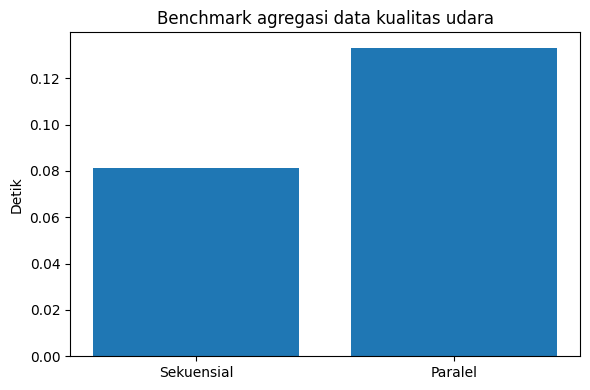

In [6]:
# Warm-up singkat untuk mengurangi bias inisialisasi library
_ = sequential_summary(benchmark_data[:1000])
t0=time.perf_counter(); seq=sequential_summary(benchmark_data); seq_time=time.perf_counter()-t0
t0=time.perf_counter(); par=parallel_summary(benchmark_data); par_time=time.perf_counter()-t0
print(f"Waktu sekuensial: {seq_time:.4f} detik")
print(f"Waktu paralel:    {par_time:.4f} detik")
print(f"Speedup (seq/par): {seq_time/par_time:.3f}x")
print("Hasil jumlah sama:", np.allclose(seq[0],par[0]))
print("Hasil jumlah kuadrat sama:", np.allclose(seq[1],par[1]))
print("Hasil jumlah nilai sama:", np.array_equal(seq[2],par[2]))
results=pd.DataFrame({"metode":["Sekuensial","Paralel"],"waktu_detik":[seq_time,par_time]})
display(results)
plt.figure(figsize=(6,4)); plt.bar(results["metode"],results["waktu_detik"]); plt.ylabel("Detik"); plt.title("Benchmark agregasi data kualitas udara"); plt.tight_layout(); plt.show()

## 5. Interpretasi yang benar
Paralel tidak selalu lebih cepat: pembagian data, serialisasi, pembuatan proses, dan ukuran dataset menambah overhead. Hasil benchmark ini berlaku untuk runtime saat dijalankan, bukan klaim universal.